# 🌳 Karar Ağaçları (Decision Trees): Ayrıntılı Teorik Anlatım ve Uygulama Rehberi

Bu çalışma kitabında, makine öğrenmesinin en temel, yorumlanabilir (beyaz kutu / *white-box*) ve güçlü algoritmalarından biri olan **Karar Ağaçları (*Decision Trees*)** hem teorik/matematiksel temelleriyle anlatılmakta hem de `ayakkabi_numarasi.xlsx` veri seti üzerinde **Sınıflandırma (Cinsiyet Tahmini)** ve **Regresyon (Ayakkabı Numarası Tahmini)** uygulamalarıyla adım adım gerçekleştirilmektedir.

---

## 📚 Bölüm 1: Karar Ağacı Nedir ve Nasıl Çalışır?

**Karar Ağacı**, veri kümesini ardışık **"Evet / Hayır"** (`Koşul Doğru mu?`) sorularıyla alt kümelere bölerek tahmin üreten hiyerarşik bir algoritmadır. Tıpkı bir akış şeması (*flowchart*) veya soru-cevap oyunu gibi çalışır.

### 1.1. Ağacın Temel Bileşenleri (Anatomisi)
1. **Kök Düğüm (*Root Node*):** Ağacın en tepesindeki ilk düğümdür. Tüm veri setini kapsar ve veriyi en iyi ayıran **en güçlü özellik** burada sorulur (Örn: `Ayakkabı Numarası <= 39.5 mu?`).
2. **İç Düğümler / Karar Düğümleri (*Internal / Decision Nodes*):** Kök düğümden gelen alt kümeleri daha saf hale getirmek için yeni özellik testlerinin yapıldığı ara düğümlerdir (Örn: `Boy <= 1.68 m mi?`).
3. **Dallar (*Branches / Edges*):** Bir düğümdeki koşulun sonucunu (`True / Sol Dal` veya `False / Sağ Dal`) gösteren bağlantılardır.
4. **Yaprak Düğümler (*Leaf / Terminal Nodes*):** Ağacın en altındaki nihai karar noktalarıdır. Artık bölünme yapılmaz; sınıflandırmada **etiket kararı** (Örn: `Erkek` veya `Kadın`), regresyonda ise o yapraktaki gözlemlerin **ortalaması** (Örn: `42.1 numara`) tahmin olarak döndürülür.

---

## 📐 Bölüm 2: Ağaç Hangi Soruyu Soracağına Nasıl Karar Verir? (Matematiksel Temel)

Karar ağacının temel amacı, her bölünmede (*split*) oluşan alt kümelerin **saflığını (*purity*)** maksimuma çıkarmak, yani **belirsizliği / safsızlığı (*impurity*)** en aza indirmektir.

### 2.1. Sınıflandırma Ağaçlarında Bölünme Kriterleri (`DecisionTreeClassifier`)

#### A) Gini Safsızlığı (*Gini Impurity* - CART Algoritmasının Varsayılanı)
Bir düğümden rastgele seçilen bir örneğin, o düğümdeki sınıf dağılımına göre yanlış etiketlenme olasılığını ölçer:

$$Gini = 1 - \sum_{i=1}^{C} (p_i)^2$$

- $p_i$: Düğümdeki $i$ sınıfına ait örneklerin oranı.
- **Yorumu:** Eğer bir düğümdeki tüm örnekler aynı sınıftansa (tamamen safsa, örn. 10 Erkek, 0 Kadın), $Gini = 1 - (1^2 + 0^2) = 0$ olur (**İdeal durum**). Eğer sınıflar yarı yarıya karışmışsa (5 Erkek, 5 Kadın), $Gini = 1 - (0.5^2 + 0.5^2) = 0.5$ olur (**Maksimum belirsizlik**).

#### B) Entropi (*Entropy*) ve Bilgi Kazancı (*Information Gain*)
Bilgi teorisinden (Claude Shannon) gelir ve bir düğümdeki düzensizliği/kaosu ölçer:

$$Entropy(S) = - \sum_{i=1}^{C} p_i \log_2(p_i)$$

- Tamamen saf bir düğümde $Entropy = 0$, iki sınıfın eşit dağıldığı (%50-%50) bir düğümde $Entropy = 1$'dir.
- **Bilgi Kazancı (*Information Gain*):** Bölünme öncesi entropi ile bölünme sonrası alt düğümlerin ağırlıklı ortalama entropisi arasındaki farktır. Ağaç, **Bilgi Kazancını maksimize eden** özelliği ve eşik değerini seçer.

### 2.2. Regresyon Ağaçlarında Bölünme Kriteri (`DecisionTreeRegressor`)
Hedef değişken sürekli bir sayı olduğunda (örn. `Ayakkabı Numarası` veya `Boy`), saflık yerine **Hata Kareler Ortalaması (*MSE / Varyans*)** kullanılır:

$$MSE = \frac{1}{N} \sum_{i=1}^{N} (y_i - \bar{y})^2$$

- Ağaç, alt düğümlerin içindeki sayıların birbirine en yakın olmasını (yani **varyansı / MSE'yi en çok düşüren** eşik değerini) seçer.

---

## ⚠️ Bölüm 3: Aşırı Öğrenme (*Overfitting*) ve Budama (*Pruning*) Hiperparametreleri

Karar ağaçları serbest bırakılırsa her bir eğitim örneğini tek başına bir yaprağa koyana kadar dallanabilir. Bu durumda eğitim başarısı %100 olurken, test verisinde başarı düşer (**Ezberleme / Overfitting**). Bunu önlemek için **Ön-Budama (*Pre-Pruning*)** parametreleri kullanılır:

- **`max_depth` (Maksimum Derinlik):** Ağacın kökten yaprağa kadar inebileceği maksimum katman sayısıdır (Örn: `max_depth=3`).
- **`min_samples_split`:** Bir iç düğümün tekrar ikiye bölünebilmesi için içinde bulunması gereken minimum örnek sayısıdır.
- **`min_samples_leaf`:** Bir yaprak düğümde bulunması gereken en az örnek sayısıdır.
- **Önemli Avantaj:** Lojistik Regresyon ve KNN'in aksine, Karar Ağaçları özelliklerin ölçeklendirilmesine (`StandardScaler`) **ihtiyaç duymaz**; çünkü mesafe hesaplamaz, her özelliği kendi eşik değerine göre böler.

## Adım 1: Gerekli Kütüphanelerin Yüklenmesi
Veri işleme, görselleştirme ve `sklearn.tree` altındaki karar ağacı modüllerini içe aktarıyoruz.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    mean_absolute_error, mean_squared_error, r2_score
)

# Grafik ayarları
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

## Adım 2: Veri Setinin Yüklenmesi ve Ön İşleme
`ayakkabi_numarasi.xlsx` dosyasını okuyor ve kategorik `Cinsiyet(E veya K)` sütununu `1` (Erkek) ve `0` (Kadın) olarak sayısal formata kodluyoruz.

In [2]:
# Excel dosyasını okuma
df = pd.read_excel('ayakkabi_numarasi.xlsx')

# Cinsiyet sütununu ikili sayısal formata kodlama (Erkek: 1, Kadın: 0)
df['Cinsiyet_E'] = (df['Cinsiyet(E veya K)'] == 'E').astype(int)

print(f"Veri Boyutu: {df.shape[0]} gözlem, {df.shape[1]} sütun")
display(df.head())

Veri Boyutu: 58 gözlem, 6 sütun


,Kilo(kg),Boy(metre),Yaş,Cinsiyet(E veya K),Ayakkabı Numarası,Cinsiyet_E
0,85,1.74,42,E,41,1
1,44,1.40,10,E,36,1
2,32,1.38,11,E,36,1
3,48,1.46,11,E,37,1
4,75,1.62,47,E,42,1


---
# UYGULAMA 1: Karar Ağacı ile Sınıflandırma (Cinsiyet Tahmini)

İlk uygulamamızda **Kilo, Boy, Yaş ve Ayakkabı Numarası** özelliklerinden kişinin **Cinsiyetini (`Kadın: 0`, `Erkek: 1`)** tahmin eden bir Sınıflandırma Karar Ağacı (`DecisionTreeClassifier`) kuruyoruz.

In [3]:
# 1. Bağımsız değişkenler (X) ve hedef değişken (y)
feature_cols_cls = ['Kilo(kg)', 'Boy(metre)', 'Yaş', 'Ayakkabı Numarası']
X_cls = df[feature_cols_cls]
y_cls = df['Cinsiyet_E']

# 2. Eğitim (%80) ve Test (%20) kümelerine ayırma
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_cls, y_cls, test_size=0.16, random_state=42
)

# 3. Karar Ağacı Sınıflandırıcısının Kurulması (Gini kriteri ve max_depth=3 ile budama)
clf_tree = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=42)
clf_tree.fit(X_train_c, y_train_c)

print("Sınıflandırma Karar Ağacı başarıyla eğitildi!")

Sınıflandırma Karar Ağacı başarıyla eğitildi!


### 1.1. Karar Ağacının Görselleştirilmesi ve Kuralların Okunması
Karar ağaçlarının en güçlü yanı, içeride aldığı kararları şeffaf biçimde çizdirebilmemizdir. Her kutuda:
- **En üst satır:** Sorulan koşul (Örn: `Ayakkabı Numarası <= 39.5`)
- **`gini`:** O düğümdeki saflık/karışıklık oranı ($0.0$ ise tamamen saf)
- **`samples`:** O düğüme düşen eğitim örneği sayısı
- **`value`:** `[Kadın Sayısı, Erkek Sayısı]` dağılımı
- **`class`:** O düğümdeki çoğunluk sınıfı

In [4]:
#get id
ids=X_train_c[X_train_c["Ayakkabı Numarası"]>39.5].index
print(y_train_c.loc[ids])

4     1
41    1
19    1
30    1
49    1
9     1
27    1
33    1
11    1
32    1
45    1
23    1
20    1
14    1
Name: Cinsiyet_E, dtype: int64


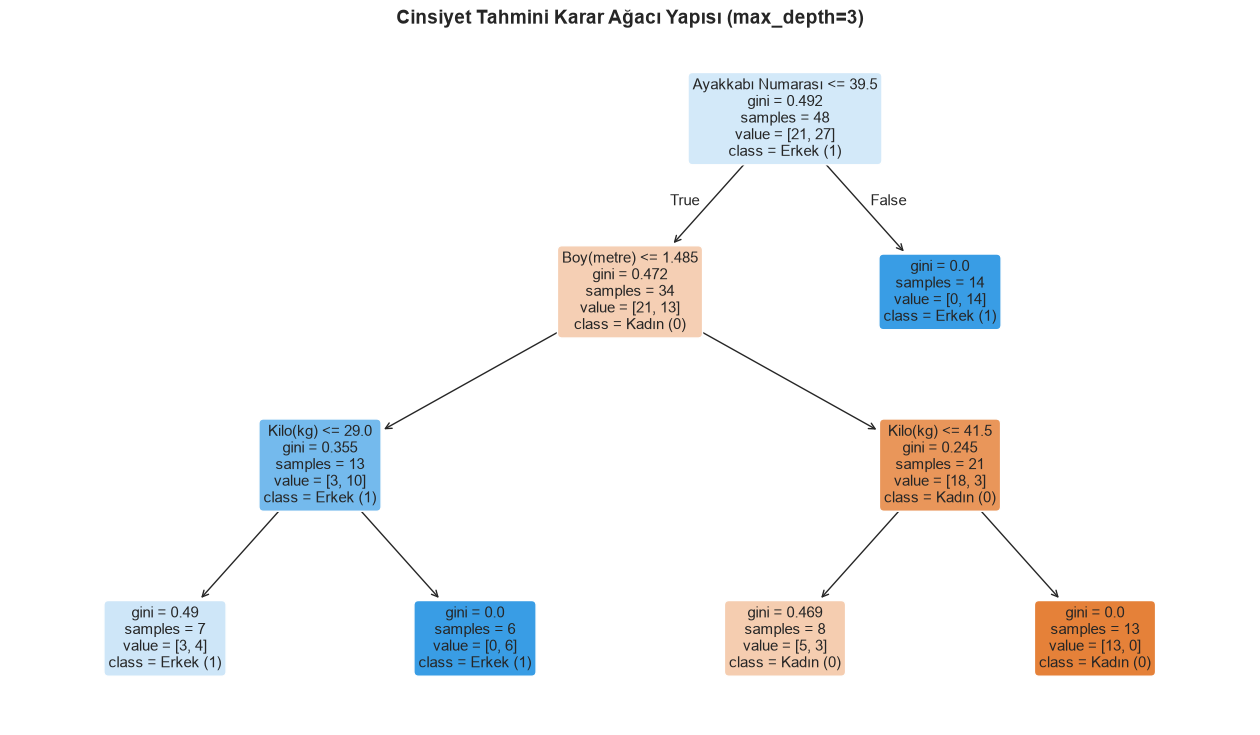

--- Karar Ağacının Çıkardığı IF-ELSE Kuralları ---
|--- Ayakkabı Numarası <= 39.50
|   |--- Boy(metre) <= 1.49
|   |   |--- Kilo(kg) <= 29.00
|   |   |   |--- class: 1
|   |   |--- Kilo(kg) >  29.00
|   |   |   |--- class: 1
|   |--- Boy(metre) >  1.49
|   |   |--- Kilo(kg) <= 41.50
|   |   |   |--- class: 0
|   |   |--- Kilo(kg) >  41.50
|   |   |   |--- class: 0
|--- Ayakkabı Numarası >  39.50
|   |--- class: 1



In [5]:
# Karar Ağacı Şemasının Çizdirilmesi
plt.figure(figsize=(16, 9))
plot_tree(
    clf_tree,
    feature_names=feature_cols_cls,
    class_names=['Kadın (0)', 'Erkek (1)'],
    filled=True,
    rounded=True,
    fontsize=11
)
plt.title("Cinsiyet Tahmini Karar Ağacı Yapısı (max_depth=3)", fontsize=14, fontweight='bold')
plt.show()

# Metinsel (IF-ELSE) Karar Kuralları
print("--- Karar Ağacının Çıkardığı IF-ELSE Kuralları ---")
print(export_text(clf_tree, feature_names=feature_cols_cls))

### 1.2. Sınıflandırma Performansı ve Özellik Önem Düzeyleri (*Feature Importances*)
Ağacın hangi özelliğe ne kadar güvendiğini `feature_importances_` niteliği ile ölçebiliriz.

Test Seti Doğruluk Oranı (Accuracy): %80.00

--- Sınıflandırma Raporu ---
              precision    recall  f1-score   support

   Kadın (0)       0.83      0.83      0.83         6
   Erkek (1)       0.75      0.75      0.75         4

    accuracy                           0.80        10
   macro avg       0.79      0.79      0.79        10
weighted avg       0.80      0.80      0.80        10



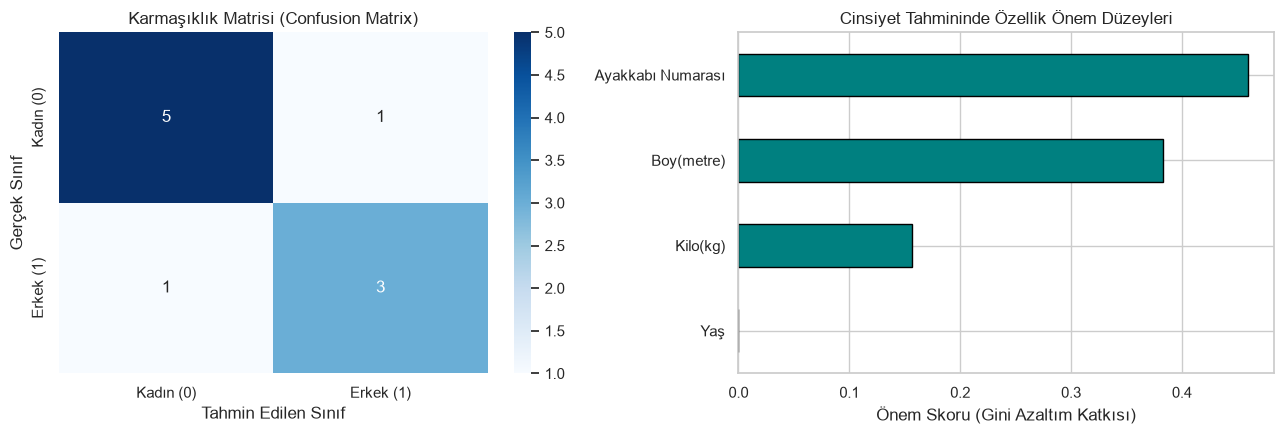

In [6]:
# Test verisi üzerinde tahmin
y_pred_c = clf_tree.predict(X_test_c)

acc = accuracy_score(y_test_c, y_pred_c)
print(f"Test Seti Doğruluk Oranı (Accuracy): %{acc * 100:.2f}\n")
print("--- Sınıflandırma Raporu ---")
print(classification_report(y_test_c, y_pred_c, target_names=['Kadın (0)', 'Erkek (1)']))

# Karmaşıklık Matrisi ve Özellik Önem Düzeyleri Yan Yana
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# 1. Grafik: Karmaşıklık Matrisi
cm = confusion_matrix(y_test_c, y_pred_c)
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
    xticklabels=['Kadın (0)', 'Erkek (1)'], yticklabels=['Kadın (0)', 'Erkek (1)']
)
axes[0].set_title('Karmaşıklık Matrisi (Confusion Matrix)')
axes[0].set_xlabel('Tahmin Edilen Sınıf')
axes[0].set_ylabel('Gerçek Sınıf')

# 2. Grafik: Özellik Önem Düzeyleri
importances = pd.Series(clf_tree.feature_importances_, index=feature_cols_cls).sort_values()
importances.plot(kind='barh', color='teal', edgecolor='black', ax=axes[1])
axes[1].set_title('Cinsiyet Tahmininde Özellik Önem Düzeyleri')
axes[1].set_xlabel('Önem Skoru (Gini Azaltım Katkısı)')

plt.tight_layout()
plt.show()

### 1.3. Maksimum Derinliğin (`max_depth`) Aşırı Öğrenmeye Etkisi
`max_depth` parametresini 1'den 10'a kadar değiştirdiğimizde eğitim ve test doğruluklarının nasıl değiştiğini inceleyelim.

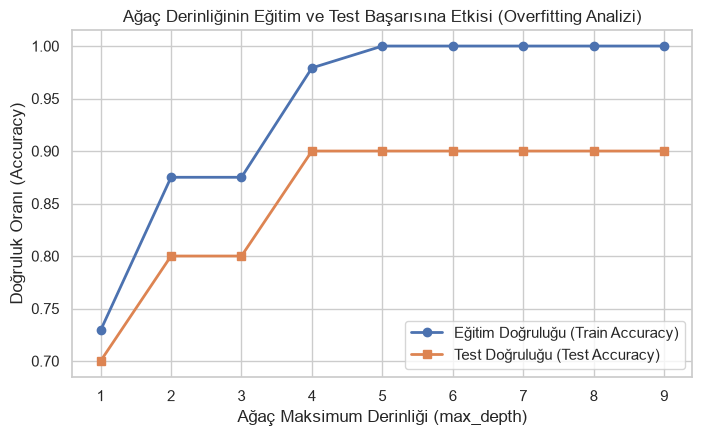

In [7]:
depths = range(1, 10)
train_scores = []
test_scores = []

for d in depths:
    temp_tree = DecisionTreeClassifier(max_depth=d, random_state=42)
    temp_tree.fit(X_train_c, y_train_c)
    train_scores.append(accuracy_score(y_train_c, temp_tree.predict(X_train_c)))
    test_scores.append(accuracy_score(y_test_c, temp_tree.predict(X_test_c)))

plt.figure(figsize=(8, 4.5))
plt.plot(depths, train_scores, marker='o', lw=2, label='Eğitim Doğruluğu (Train Accuracy)')
plt.plot(depths, test_scores, marker='s', lw=2, label='Test Doğruluğu (Test Accuracy)')
plt.xlabel('Ağaç Maksimum Derinliği (max_depth)')
plt.ylabel('Doğruluk Oranı (Accuracy)')
plt.title('Ağaç Derinliğinin Eğitim ve Test Başarısına Etkisi (Overfitting Analizi)')
plt.xticks(depths)
plt.legend()
plt.show()

---
# UYGULAMA 2: Karar Ağacı ile Regresyon (Ayakkabı Numarası Tahmini)

Karar ağaçları yalnızca sınıflandırma için değil, sürekli sayısal değerleri tahmin etmek için de kullanılır (`DecisionTreeRegressor`). Şimdi **Kilo, Boy, Yaş ve Cinsiyet_E** özelliklerinden **Ayakkabı Numarası** tahmini yapalım.

In [8]:
# 1. Bağımsız değişkenler (X) ve hedef değişken (y)
feature_cols_reg = ['Kilo(kg)', 'Boy(metre)', 'Yaş', 'Cinsiyet_E']
X_reg = df[feature_cols_reg]
y_reg = df['Ayakkabı Numarası']

# 2. Eğitim ve Test kümelerine ayırma
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=42
)

# 3. Regresyon Karar Ağacının Eğitilmesi
reg_tree = DecisionTreeRegressor(criterion='squared_error', max_depth=3, random_state=42)
reg_tree.fit(X_train_r, y_train_r)

# 4. Test tahminleri ve metrikler
y_pred_r = reg_tree.predict(X_test_r)

print(f"Regresyon R² Skoru: {r2_score(y_test_r, y_pred_r):.3f}")
print(f"MAE (Ortalama Mutlak Hata): {mean_absolute_error(y_test_r, y_pred_r):.2f} numara")
print(f"RMSE (Karekök Ortalama Kare Hata): {np.sqrt(mean_squared_error(y_test_r, y_pred_r)):.2f} numara")

Regresyon R² Skoru: 0.442
MAE (Ortalama Mutlak Hata): 0.98 numara
RMSE (Karekök Ortalama Kare Hata): 1.35 numara


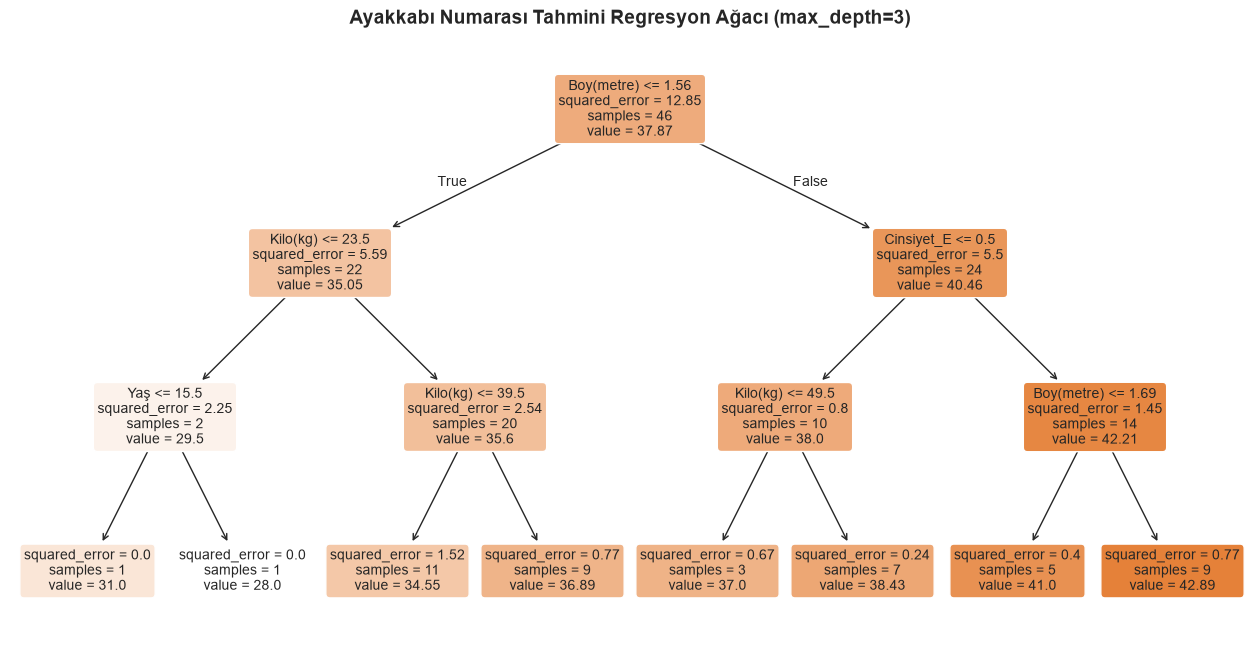

In [9]:
# Regresyon Karar Ağacının Görselleştirilmesi
plt.figure(figsize=(16, 8))
plot_tree(
    reg_tree,
    feature_names=feature_cols_reg,
    filled=True,
    rounded=True,
    precision=2,
    fontsize=10
)
plt.title("Ayakkabı Numarası Tahmini Regresyon Ağacı (max_depth=3)", fontsize=14, fontweight='bold')
plt.show()

## Adım 3: Yeni Örnekler Üzerinde Hem Cinsiyet Hem Ayakkabı Numarası Tahmini
Eğittiğimiz iki karar ağacı modelini yeni birey profilleri üzerinde test ediyoruz.

In [10]:
# 1. Sınıflandırma Ağacı ile Cinsiyet Tahmini Testi
yeni_bireyler_cls = pd.DataFrame([
    {'Kilo(kg)': 78, 'Boy(metre)': 1.76, 'Yaş': 30, 'Ayakkabı Numarası': 43},
    {'Kilo(kg)': 56, 'Boy(metre)': 1.63, 'Yaş': 25, 'Ayakkabı Numarası': 37}
])
cinsiyet_tahmin = clf_tree.predict(yeni_bireyler_cls)

print("=== 1. Karar Ağacı ile Cinsiyet Tahminleri ===")
for i, row in yeni_bireyler_cls.iterrows():
    etiket = 'Erkek (1)' if cinsiyet_tahmin[i] == 1 else 'Kadın (0)'
    print(f"Birey {i+1} (Boy: {row['Boy(metre)']}m, Kilo: {row['Kilo(kg)']}kg, Ayakkabı: {row['Ayakkabı Numarası']}) -> Tahmin: {etiket}")

# 2. Regresyon Ağacı ile Ayakkabı Numarası Tahmini Testi
yeni_bireyler_reg = pd.DataFrame([
    {'Kilo(kg)': 78, 'Boy(metre)': 1.76, 'Yaş': 30, 'Cinsiyet_E': 1},
    {'Kilo(kg)': 56, 'Boy(metre)': 1.63, 'Yaş': 25, 'Cinsiyet_E': 0}
])
numara_tahmin = reg_tree.predict(yeni_bireyler_reg)

print("\n=== 2. Karar Ağacı ile Ayakkabı Numarası Tahminleri ===")
for i, row in yeni_bireyler_reg.iterrows():
    cinsiyet_str = 'Erkek' if row['Cinsiyet_E'] == 1 else 'Kadın'
    print(f"Birey {i+1} ({cinsiyet_str}, Boy: {row['Boy(metre)']}m, Kilo: {row['Kilo(kg)']}kg) -> Tahmin: {numara_tahmin[i]:.2f} (En Yakın No: {round(numara_tahmin[i])})")

=== 1. Karar Ağacı ile Cinsiyet Tahminleri ===
Birey 1 (Boy: 1.76m, Kilo: 78.0kg, Ayakkabı: 43.0) -> Tahmin: Erkek (1)
Birey 2 (Boy: 1.63m, Kilo: 56.0kg, Ayakkabı: 37.0) -> Tahmin: Kadın (0)

=== 2. Karar Ağacı ile Ayakkabı Numarası Tahminleri ===
Birey 1 (Erkek, Boy: 1.76m, Kilo: 78.0kg) -> Tahmin: 42.89 (En Yakın No: 43)
Birey 2 (Kadın, Boy: 1.63m, Kilo: 56.0kg) -> Tahmin: 38.43 (En Yakın No: 38)
